# Isolation Forest / ECOD vs ETS (walk-forward)

Benchmark tầng proximity trên feature causal.

**Quy tắc**
- Tại tháng `t`: fit trên hàng `< t` (sau warm-up), score hàng `t` — **không look-ahead**.
- Ngưỡng WARN/CRITICAL = quantile 97%/99% của **điểm quá khứ**.
- So với ETS bằng win rule (key recall + alerts/năm).

**Tiên quyết:** `causal_features_explore.ipynb` (build causal) và `eval_anomaly_protocol.ipynb` (baseline).


## 1. Cấu hình & thư viện

ECOD chỉ chạy nếu đã cài `pyod`.


In [1]:
from __future__ import annotations

import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.ensemble import IsolationForest

ROOT = Path("..").resolve()
if not (ROOT / "data" / "features" / "causal").exists():
    ROOT = Path(".").resolve()

CAUSAL_DIR = ROOT / "data" / "features" / "causal"
EVAL_DIR = ROOT / "reports" / "eval"
BASELINE = EVAL_DIR / "baseline_ets.json"
MIN_TRAIN = 60
INJECT = [1.2, 1.5, 2.0, 3.0, 0.7, 0.5, 0.3]
SERIES_FILES = [
    "gạo_causal.csv",
    "sắt thép các loại_causal.csv",
    "xăng dầu các loại_causal.csv",
    "dầu thô_causal.csv",
]

FEATURE_COLS = [
    "log_so_luong_mom",
    "log_so_luong_yoy",
    "log_tri_gia_mom",
    "log_tri_gia_yoy",
    "log_don_gia_mom",
    "log_don_gia_yoy",
    "so_luong_robust_z12",
    "tri_gia_robust_z12",
    "don_gia_robust_z12",
    "z_don_gia_minus_z_so_luong",
]

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (12, 4)
print("CAUSAL_DIR exists:", CAUSAL_DIR.exists())
print("BASELINE exists:", BASELINE.exists())


CAUSAL_DIR exists: True
BASELINE exists: True


## 2. Protocol helpers (win rule)

Copy tối thiểu từ protocol — không phụ thuộc file `.py`.


In [2]:
KEY_FACTORS = ["x2.0", "x0.5"]


def mean_key_recall(recall: dict) -> float:
    vals = []
    for col_rec in recall.values():
        for f in KEY_FACTORS:
            if f in col_rec:
                vals.append(col_rec[f])
    return float(np.mean(vals)) if vals else float("nan")


def beats_baseline(candidate: dict, baseline: dict) -> dict:
    c_rec = mean_key_recall(candidate.get("synthetic_recall", {}))
    b_rec = mean_key_recall(baseline.get("synthetic_recall", {}))
    c_rate = candidate.get("alerts_per_year", {}).get("WARN_or_CRITICAL", np.nan)
    b_rate = baseline.get("alerts_per_year", {}).get("WARN_or_CRITICAL", np.nan)
    better_recall = (c_rec - b_rec) >= 0.05 if np.isfinite(c_rec) and np.isfinite(b_rec) else False
    if np.isfinite(c_rate) and np.isfinite(b_rate) and b_rate > 0:
        rate_ok = c_rate <= 2.0 * b_rate
    elif np.isfinite(c_rate) and np.isfinite(b_rate):
        rate_ok = c_rate <= max(2.0, b_rate)
    else:
        rate_ok = False
    return {
        "candidate_key_recall": round(c_rec, 3) if np.isfinite(c_rec) else None,
        "baseline_key_recall": round(b_rec, 3) if np.isfinite(b_rec) else None,
        "candidate_alerts_per_year": c_rate,
        "baseline_alerts_per_year": b_rate,
        "better_recall": bool(better_recall),
        "rate_ok": bool(rate_ok),
        "wins": bool(better_recall and rate_ok),
        "rule": "key_recall(x2,x0.5) +0.05 AND alerts/year <= 2x baseline",
    }

def try_ecod():
    try:
        from pyod.models.ecod import ECOD
        return ECOD
    except Exception:
        return None


## 3. Walk-forward score & alert

- IF: `score = -decision_function` (cao = bất thường hơn).
- Alert: so điểm tháng `t` với quantile lịch sử `[:t)`.


In [3]:
def load_causal(path: Path) -> pd.DataFrame:
    return pd.read_csv(path, parse_dates=["thang_nam"]).set_index("thang_nam").sort_index()


def walk_forward_scores(X: pd.DataFrame, model_name: str = "if") -> pd.Series:
    # Higher score = more anomalous
    scores = pd.Series(index=X.index, dtype=float)
    ECOD = try_ecod() if model_name == "ecod" else None
    for t in range(MIN_TRAIN, len(X)):
        train = X.iloc[:t].dropna()
        if len(train) < MIN_TRAIN // 2:
            continue
        row = X.iloc[[t]].dropna(axis=1, how="all")
        cols = [c for c in train.columns if c in row.columns and row[c].notna().all()]
        if len(cols) < 3:
            continue
        tr = train[cols].dropna()
        te = X.iloc[[t]][cols]
        if te.isna().any(axis=1).iloc[0] or len(tr) < 24:
            continue
        if model_name == "if":
            clf = IsolationForest(
                n_estimators=200, contamination="auto", random_state=42, n_jobs=-1
            )
            clf.fit(tr)
            scores.iloc[t] = float(-clf.decision_function(te)[0])
        elif model_name == "ecod" and ECOD is not None:
            clf = ECOD(contamination=0.05)
            clf.fit(tr.values)
            scores.iloc[t] = float(clf.decision_function(te.values)[0])
    return scores


def alerts_from_scores(scores: pd.Series, warn_q: float = 0.97, crit_q: float = 0.99) -> pd.Series:
    alert = pd.Series("OK", index=scores.index, dtype=object)
    for t in range(len(scores)):
        s = scores.iloc[t]
        if pd.isna(s):
            continue
        hist = scores.iloc[:t].dropna()
        if len(hist) < 24:
            continue
        w, c = hist.quantile(warn_q), hist.quantile(crit_q)
        if s >= c:
            alert.iloc[t] = "CRITICAL"
        elif s >= w:
            alert.iloc[t] = "WARN"
    return alert


def alerts_per_year(alert: pd.Series) -> dict:
    sub = alert[alert.index.notna()]
    counts = sub.value_counts().to_dict()
    n_years = max(1, sub.index.year.nunique())
    return {
        "WARN": round(int(counts.get("WARN", 0)) / n_years, 2),
        "CRITICAL": round(int(counts.get("CRITICAL", 0)) / n_years, 2),
        "WARN_or_CRITICAL": round(
            (int(counts.get("WARN", 0)) + int(counts.get("CRITICAL", 0))) / n_years, 2
        ),
        "counts": {k: int(v) for k, v in counts.items()},
    }


## 4. Synthetic recall (proxy trên feature)

Nhân log-MoM/YoY và điều chỉnh robust z; đếm tỷ lệ vượt WARN lịch sử. Chỉ chạy đầy đủ cho **gạo** (chậm).


In [4]:
def synthetic_recall_if(df: pd.DataFrame, base_scores: pd.Series) -> dict:
    X = df[FEATURE_COLS]
    out = {"so_luong": {f"x{f}": 0 for f in INJECT}, "tri_gia": {f"x{f}": 0 for f in INJECT}}
    counts = {"so_luong": 0, "tri_gia": 0}
    targets = {
        "so_luong": (
            ["so_luong_robust_z12", "z_don_gia_minus_z_so_luong"],
            ["log_so_luong_mom", "log_so_luong_yoy"],
        ),
        "tri_gia": (
            ["tri_gia_robust_z12"],
            ["log_tri_gia_mom", "log_tri_gia_yoy"],
        ),
    }
    for t in range(MIN_TRAIN, len(X)):
        hist = base_scores.iloc[:t].dropna()
        if len(hist) < 24:
            continue
        warn_t = float(hist.quantile(0.97))
        train = X.iloc[:t].dropna()
        if len(train) < 24:
            continue
        row0 = X.iloc[t]
        if row0.isna().any():
            continue
        clf = IsolationForest(n_estimators=100, contamination="auto", random_state=42, n_jobs=-1)
        clf.fit(train)
        for target, (zcols, momcols) in targets.items():
            counts[target] += 1
            for f in INJECT:
                row = row0.copy()
                for c in momcols:
                    row[c] = row[c] + np.log(f)
                for c in zcols:
                    if c == "z_don_gia_minus_z_so_luong":
                        row[c] = row[c] - np.log(f) / 0.2
                    else:
                        row[c] = row[c] + np.log(f) / 0.2
                score = float(-clf.decision_function(row.values.reshape(1, -1))[0])
                if score >= warn_t:
                    out[target][f"x{f}"] += 1
    for target in out:
        n = max(1, counts[target])
        for k in out[target]:
            out[target][k] = round(out[target][k] / n, 3)
    return out


def run_series(path: Path, with_ecod: bool = True) -> dict:
    df = load_causal(path)
    X = df[FEATURE_COLS]
    name = path.stem.replace("_causal", "")
    if_scores = walk_forward_scores(X, "if")
    if_alert = alerts_from_scores(if_scores)
    if_apy = alerts_per_year(if_alert)
    result = {
        "series": name,
        "if": {
            "alerts_per_year": {k: v for k, v in if_apy.items() if k != "counts"},
            "counts": if_apy["counts"],
        },
    }
    ECOD = try_ecod()
    if with_ecod and ECOD is not None:
        ecod_scores = walk_forward_scores(X, "ecod")
        ecod_alert = alerts_from_scores(ecod_scores)
        ecod_apy = alerts_per_year(ecod_alert)
        result["ecod"] = {
            "alerts_per_year": {k: v for k, v in ecod_apy.items() if k != "counts"},
            "counts": ecod_apy["counts"],
        }
    else:
        result["ecod"] = None
    result["_if_scores"] = if_scores
    result["_df"] = df
    return result


## 5. Chạy benchmark 4 chuỗi + so ETS

Walk-forward IF trên từng chuỗi, so alerts/năm với baseline ETS.
Chỉ gạo chạy synthetic recall + win rule (chậm hơn).
Kết quả machine-readable: `reports/eval/if_ecod_vs_ets.json`.


In [5]:
EVAL_DIR.mkdir(parents=True, exist_ok=True)
baseline_all = json.loads(BASELINE.read_text(encoding="utf-8"))["series"]
ECOD = try_ecod()
if ECOD is None:
    print("pyod not installed — Isolation Forest only (pip install pyod for ECOD)")

rows = []
rice_detail = None
cached_scores = {}

for fname in SERIES_FILES:
    path = CAUSAL_DIR / fname
    print(f"IF walk-forward: {fname}")
    res = run_series(path, with_ecod=False)
    series = res["series"]
    base = baseline_all.get(series)
    if series not in baseline_all:
        for k in baseline_all:
            if k in series or series in k:
                base = baseline_all[k]
                break
    if_block = res["if"]
    decision = None
    recall = None
    if series == "gạo":
        print("  computing synthetic recall for gạo (slow)...")
        recall = synthetic_recall_if(res["_df"], res["_if_scores"])
        if_block["synthetic_recall"] = recall
        candidate = {"synthetic_recall": recall, "alerts_per_year": if_block["alerts_per_year"]}
        baseline_cmp = {
            "synthetic_recall": base["synthetic_recall"],
            "alerts_per_year": base["alerts_per_year"],
        }
        decision = beats_baseline(candidate, baseline_cmp)
        rice_detail = {"if": if_block, "decision": decision, "baseline": base}
    cached_scores[series] = res["_if_scores"]
    rows.append(
        {
            "series": series,
            "if_alerts_per_year": if_block["alerts_per_year"]["WARN_or_CRITICAL"],
            "ets_alerts_per_year": base["alerts_per_year"]["WARN_or_CRITICAL"] if base else None,
            "if_key_recall": mean_key_recall(recall) if recall else None,
            "ets_key_recall": base["key_recall"] if base else None,
            "wins_vs_ets": decision["wins"] if decision else None,
        }
    )
    del res["_if_scores"], res["_df"]

payload = {"rows": rows, "rice": rice_detail}
(EVAL_DIR / "if_ecod_vs_ets.json").write_text(
    json.dumps(payload, ensure_ascii=False, indent=2, default=str), encoding="utf-8"
)
print(f"Wrote {EVAL_DIR / 'if_ecod_vs_ets.json'}")
display(pd.DataFrame(rows).set_index("series"))
if rice_detail is not None:
    print("Verdict gạo:", "IF WINS" if rice_detail["decision"]["wins"] else "IF does NOT beat ETS")
    display(pd.Series(rice_detail["decision"]))

IF walk-forward: gạo_causal.csv
  computing synthetic recall for gạo (slow)...


c:\Homework\Code File\ML docs\Anomaly Detection\.venv\lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but IsolationForest was fitted with feature names
  warnings.warn(
c:\Homework\Code File\ML docs\Anomaly Detection\.venv\lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but IsolationForest was fitted with feature names
  warnings.warn(
c:\Homework\Code File\ML docs\Anomaly Detection\.venv\lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but IsolationForest was fitted with feature names
  warnings.warn(
c:\Homework\Code File\ML docs\Anomaly Detection\.venv\lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but IsolationForest was fitted with feature names
  warnings.warn(
c:\Homework\Code File\ML docs\Anomaly Detection\.venv\lib\site-packages\sklearn\utils\validation.py:2749: Us

IF walk-forward: sắt thép các loại_causal.csv
IF walk-forward: xăng dầu các loại_causal.csv
IF walk-forward: dầu thô_causal.csv
Wrote C:\Homework\Code File\ML docs\Anomaly Detection\reports\eval\if_ecod_vs_ets.json


,if_alerts_per_year,ets_alerts_per_year,if_key_recall,ets_key_recall,wins_vs_ets
series,,,,,
gạo,0.33,0.15,0.32625,0.45725,False
sắt thép các loại,0.28,0.46,NaN,0.76350,None
xăng dầu các loại,0.28,1.08,NaN,0.76175,None
dầu thô,0.33,1.00,NaN,0.36050,None


Verdict gạo: IF does NOT beat ETS


candidate_key_recall                                                     0.326
baseline_key_recall                                                      0.457
candidate_alerts_per_year                                                 0.33
baseline_alerts_per_year                                                  0.15
better_recall                                                            False
rate_ok                                                                  False
wins                                                                     False
rule                         key_recall(x2,x0.5) +0.05 AND alerts/year <= 2...
dtype: object

## 6. Biểu đồ alerts / năm


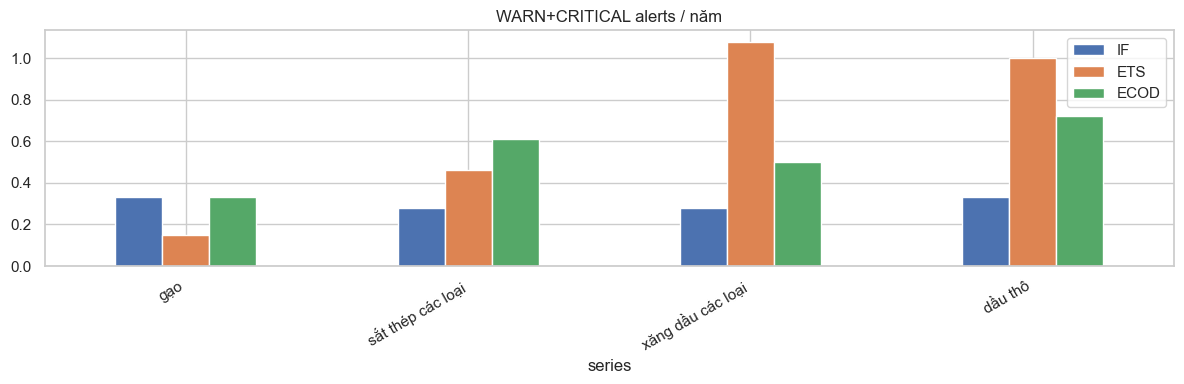

In [6]:
rows_df = pd.DataFrame(rows).set_index("series")
cmp = pd.DataFrame({"IF": rows_df["if_alerts_per_year"], "ETS": rows_df["ets_alerts_per_year"]})
ecod_path = EVAL_DIR / "ecod_alerts.json"
if ecod_path.exists():
    ecod_df = pd.DataFrame(json.loads(ecod_path.read_text(encoding="utf-8"))).set_index("series")
    if "ecod_alerts_per_year" in ecod_df.columns:
        cmp["ECOD"] = ecod_df["ecod_alerts_per_year"]
cmp.plot(kind="bar", title="WARN+CRITICAL alerts / năm")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()


## 7. Timeline IF score — gạo

Dùng score đã cache từ bước benchmark (không fit lại).


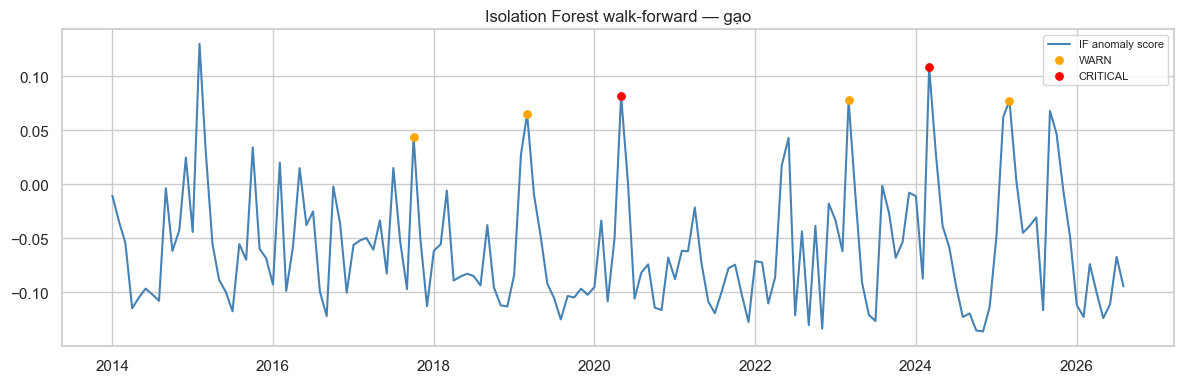

OK          206
WARN          4
CRITICAL      2
Name: count, dtype: int64


In [7]:
SERIES = "gạo"
scores = cached_scores[SERIES]
alert = alerts_from_scores(scores)

fig, ax = plt.subplots()
ax.plot(scores.index, scores.values, label="IF anomaly score", color="steelblue")
for level, color in [("WARN", "orange"), ("CRITICAL", "red")]:
    pts = scores[alert == level]
    ax.scatter(pts.index, pts.values, color=color, s=28, label=level, zorder=5)
ax.set_title(f"Isolation Forest walk-forward — {SERIES}")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()
print(alert.value_counts())


## 8. Gạo: IF key recall vs ETS


candidate_key_recall                                                     0.326
baseline_key_recall                                                      0.457
candidate_alerts_per_year                                                 0.33
baseline_alerts_per_year                                                  0.15
better_recall                                                            False
rate_ok                                                                  False
wins                                                                     False
rule                         key_recall(x2,x0.5) +0.05 AND alerts/year <= 2...
dtype: object

,x1.2,x1.5,x2.0,x3.0,x0.7,x0.5,x0.3
so_luong,0.062,0.164,0.383,0.906,0.125,0.406,0.969
tri_gia,0.055,0.094,0.258,0.539,0.094,0.258,0.430


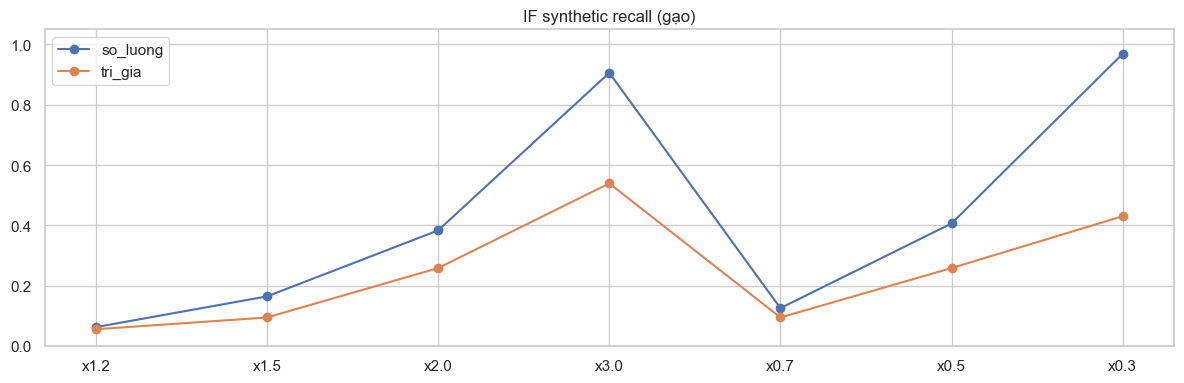

In [8]:
if rice_detail is None:
    print("Không có chi tiết gạo — kiểm tra baseline / causal CSV.")
else:
    display(pd.Series(rice_detail["decision"]))
    rec = pd.DataFrame(rice_detail["if"]["synthetic_recall"]).T
    display(rec)
    rec.T.plot(marker="o", title="IF synthetic recall (gạo)")
    plt.ylim(0, 1.05)
    plt.tight_layout()
    plt.show()
